In [1]:
from graphdatascience import GraphDataScience
import pandas as pd, numpy as np
gds = GraphDataScience("bolt://localhost:7687", auth=("neo4j", "Lastfm_2026_pw"))

e = gds.run_cypher("MATCH (u:User)-[:LISTEN_TO]->(a:Artist) RETURN u.id AS u, a.id AS a")
rng = np.random.default_rng(42)
e["test"] = False
for u, idx in e.groupby("u").groups.items():
    idx = list(idx)
    k = max(1, int(round(0.2 * len(idx))))
    e.loc[rng.choice(idx, size=k, replace=False), "test"] = True
print("listens:", len(e), "| hidden for testing:", int(e.test.sum()), "=", round(e.test.mean()*100, 1), "%")
print("users with at least 1 hidden artist:", e[e.test].u.nunique())

listens: 92834 | hidden for testing: 18577 = 20.0 %
users with at least 1 hidden artist: 1892


In [2]:
rows = e.assign(split=np.where(e.test, "test", "train"))[["u", "a", "split"]].to_dict("records")
for i in range(0, len(rows), 5000):
    gds.run_cypher("UNWIND $rows AS r MATCH (:User {id:r.u})-[l:LISTEN_TO]->(:Artist {id:r.a}) SET l.split = r.split",
                   {"rows": rows[i:i+5000]})

gds.run_cypher("CALL gds.graph.drop('train', false)")
print(gds.run_cypher("""
MATCH (u:User)-[l:LISTEN_TO]->(a:Artist) WHERE l.split = 'train'
WITH gds.graph.project('train', u, a, {}, {undirectedRelationshipTypes: ['*']}) AS g
RETURN g.graphName AS graph, g.nodeCount AS nodes, g.relationshipCount AS rels"""))
Gtr = gds.graph.get("train")

Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('train', false)"


   graph  nodes    rels
0  train  17326  148514


In [3]:
nodes = gds.run_cypher("""MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label,
                          n.id AS id, n.name AS name, n.louvain AS comm""")
users_n = nodes[nodes.label == "User"].set_index("id")
arts_n  = nodes[nodes.label == "Artist"].set_index("id")

train = e[~e.test]; test = e[e.test]
art_pop = train.groupby("a").size()                 # listeners per artist in training
in_train = set(art_pop.index)
print("artists present in the training graph:", len(in_train))
print("hidden listens whose artist is still in training:", round(test.a.isin(in_train).mean() * 100, 1), "%")

user_pop = train.assign(p=train.a.map(art_pop)).groupby("u").p.mean()   # how mainstream a user's taste is
niche_u, main_u, broad_u = int(user_pop.idxmin()), int(user_pop.idxmax()), 3
print("niche user", niche_u, round(user_pop[niche_u], 1), "| mainstream user", main_u, round(user_pop[main_u], 1),
      "| median user", round(user_pop.median(), 1))

Received notification from DBMS server: <GqlStatusObject gql_status='01N02', status_description='warn: feature deprecated without replacement. id is deprecated and will be removed without a replacement.', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label,\n                          n.id AS id, n.name AS name, n.louvain AS comm'


artists present in the training graph: 15442
hidden listens whose artist is still in training: 87.5 %
niche user 1266 1.0 | mainstream user 797 286.3 | median user 61.1


In [4]:
def recommend_ppr(u, k=10):
    src = int(users_n.loc[u, "nodeId"])
    s = gds.page_rank.stream(Gtr, source_nodes=[src], max_iterations=30)
    s = s.merge(nodes[nodes.label == "Artist"][["nodeId", "id", "name", "comm"]], on="nodeId")
    heard = set(train[train.u == u].a)
    return s[~s.id.isin(heard)].sort_values("score", ascending=False).head(k)

for tag, u in [("niche", niche_u), ("mainstream", main_u), ("broad", broad_u)]:
    hidden = set(test[test.u == u].a)
    r = recommend_ppr(u); r["hit"] = r.id.isin(hidden)
    print(f"\n== {tag} user {u} | own community: {users_n.loc[u, 'comm']} | his listening by community:",
          train[train.u == u].a.map(arts_n.comm).value_counts().head(3).to_dict())
    print(r[["name", "comm", "score", "hit"]].to_string(index=False))
    print("hidden artists (what we hope to find):", ", ".join(arts_n.loc[list(hidden), "name"].dropna().head(10)))

 PageRank:  13%|#3        | 13.33/100 [00:00<?, ?%/s]


== niche user 1266 | own community: C14 | his listening by community: {'C14': 2}
             name comm  score   hit
         Röyksopp   C1    0.0 False
Ministry of Sound   C4    0.0 False
        Vitamin Z   C4    0.0 False
    Fleetwood Mac   C4    0.0 False
              Air   C1    0.0 False
      Nik Kershaw   C4    0.0 False
       Camouflage   C4    0.0 False
    Groove Armada   C4    0.0 False
     Hooverphonic   C1    0.0 False
     Café Del Mar   C4    0.0 False
hidden artists (what we hope to find): Mueller/Feldbauer


 PageRank:  33%|###3      | 33.44/100 [00:00<?, ?%/s]


== mainstream user 797 | own community: C3 | his listening by community: {'C3': 9}
           name comm    score   hit
 Britney Spears   C3 0.003824  True
        Rihanna   C3 0.003587 False
        Beyoncé   C3 0.002777 False
       Paramore   C3 0.002384 False
    Miley Cyrus   C3 0.002347 False
        Shakira   C3 0.002278 False
Black Eyed Peas   C3 0.002217 False
           P!nk   C3 0.002099 False
  Kylie Minogue   C3 0.001971 False
 Kelly Clarkson   C3 0.001952 False
hidden artists (what we hope to find): Britney Spears, Miranda Cosgrove


 PageRank:  65%|######5   | 65.0/100 [00:00<?, ?%/s]


== broad user 3 | own community: C6 | his listening by community: {'C6': 36, 'C1': 4}
                  name comm    score   hit
             Sigur Rós   C1 0.000820 False
                Bonobo   C1 0.000613 False
             Radiohead   C1 0.000607 False
                Helios   C1 0.000456 False
              Aes Dana   C6 0.000447 False
Carbon Based Lifeforms   C6 0.000441 False
              Coldplay   C1 0.000436 False
          Solar Fields   C6 0.000429 False
                  Deru   C6 0.000412  True
       Ulrich Schnauss   C6 0.000399 False
hidden artists (what we hope to find): Pleq & Chihiro, Deru, Danny Norbury, Shinkei & Mise En Scene, Off the Sky, strom noir, Lauki, Max Richter, Matryoshka, Aidan Baker


In [5]:
missing = sorted(set(e.u) - set(train.u))
print("users with no training edge:", missing, "| their listens:", e[e.u.isin(missing)].groupby("u").size().to_dict())

q = user_pop.quantile(0.10)
niche_u = int((user_pop - q).abs().idxmin())
print("new niche user:", niche_u, "| mean artist popularity:", round(user_pop[niche_u], 1), "| training listens:", int((train.u == niche_u).sum()))
r = recommend_ppr(niche_u); r["hit"] = r.id.isin(set(test[test.u == niche_u].a))
print(r[["name", "comm", "score", "hit"]].to_string(index=False))

users with no training edge: [112, 615, 1013, 1307, 1603, 1731, 1758, 2085] | their listens: {112: 1, 615: 1, 1013: 1, 1307: 1, 1603: 1, 1731: 1, 1758: 1, 2085: 1}
new niche user: 116 | mean artist popularity: 17.7 | training listens: 40


 PageRank:  53%|#####3    | 53.33/100 [00:00<?, ?%/s]

           name comm    score   hit
     Kanye West   C3 0.001714 False
           2Pac   C7 0.001351 False
      Lady Gaga   C3 0.001304 False
       Coldplay   C1 0.001172 False
 Britney Spears   C3 0.001121 False
        Rihanna   C3 0.001054 False
     Katy Perry   C3 0.001019 False
      Radiohead   C1 0.000997 False
Black Eyed Peas   C3 0.000967 False
        Madonna   C3 0.000965 False


In [6]:
tc = gds.louvain.stream(Gtr).set_index("nodeId").communityId
print("communities in the training graph:", tc.nunique())

u2n, a2n = users_n.nodeId, arts_n.nodeId
tr = train.assign(cu=train.u.map(u2n).map(tc), ca=train.a.map(a2n).map(tc))
ext = tr.assign(x=tr.cu != tr.ca).groupby("a").agg(n=("u", "size"), ext=("x", "mean"))
is_bridge = ((ext.n >= 10) & (ext.ext >= 0.4))
print("bridge artists in training (>= 10 listeners, >= 40% outside listeners):", int(is_bridge.sum()))

a2tc = arts_n.nodeId.map(tc)                      # artist id -> training community
node2art = pd.Series(arts_n.index, index=arts_n.nodeId)
heard = train.groupby("u").a.apply(set).to_dict()
hidden_ok = {u: set(g.a) & in_train for u, g in test.groupby("u")}
pop_order = art_pop.sort_values(ascending=False).index.tolist()

 Louvain:   2%|1         | 1.98/100 [00:00<?, ?%/s]

communities in the training graph: 24
bridge artists in training (>= 10 listeners, >= 40% outside listeners): 540


In [7]:
def ppr_ranked(u, n=60):
    s = gds.page_rank.stream(Gtr, source_nodes=[int(u2n[u])], max_iterations=30)
    s = s[s.nodeId.isin(node2art.index)].copy()
    s["a"] = s.nodeId.map(node2art)
    return s[~s.a.isin(heard[u])].sort_values("score", ascending=False).head(n)

def rec_pop(u, k=10):
    return [a for a in pop_order if a not in heard[u]][:k]

def rec_aware(u, cand, k=10, slots=3):
    home = tc[int(u2n[u])]
    c = cand.assign(c=cand.nodeId.map(tc), br=cand.a.map(is_bridge).fillna(False))
    out = c[(c.c != home) & c.br].head(slots)
    keep = c[~c.a.isin(out.a)].head(k - len(out))
    return pd.concat([keep, out]).a.tolist()

eval_users = [u for u in heard if hidden_ok.get(u)]
rs = np.random.default_rng(42)
sample = rs.choice(eval_users, size=400, replace=False)

rows = []
for u in sample:
    hid = hidden_ok[u]; cand = ppr_ranked(u); home = tc[int(u2n[u])]
    for name, r in [("popularity", rec_pop(u)), ("PPR", cand.head(10).a.tolist()),
                    ("community-aware PPR", rec_aware(u, cand))]:
        h = len(set(r) & hid)
        cs = a2tc[r]
        rows.append(dict(user=u, strategy=name, hit=h > 0, recall=h / len(hid),
                         communities=cs.nunique(), outside=(cs != home).mean()))
res = pd.DataFrame(rows)
summary = res.groupby("strategy").agg(users=("user", "nunique"), Hit10=("hit", "mean"),
          Recall10=("recall", "mean"), avg_communities=("communities", "mean"),
          share_outside_home=("outside", "mean")).round(3)
print(summary)

 PageRank:  78%|#######8  | 78.33/100 [00:00<?, ?%/s]

 PageRank:  53%|#####3    | 53.33/100 [00:00<?, ?%/s]

 PageRank:  85%|########4 | 84.95/100 [00:00<?, ?%/s]

 PageRank:  65%|######5   | 65.0/100 [00:00<?, ?%/s]

 PageRank:  70%|#######   | 70.0/100 [00:00<?, ?%/s]

 PageRank:  73%|#######3  | 73.33/100 [00:00<?, ?%/s]

... (21 outputs left out)

 PageRank:  88%|########8 | 88.33/100 [00:00<?, ?%/s]

 PageRank:  90%|######### | 90.0/100 [00:00<?, ?%/s]

 PageRank:  48%|####7     | 47.86/100 [00:00<?, ?%/s]

                     users  Hit10  Recall10  avg_communities  \
strategy                                                       
PPR                    400  0.625     0.139            2.432   
community-aware PPR    400  0.622     0.132            2.980   
popularity             400  0.418     0.077            2.088   

                     share_outside_home  
strategy                                 
PPR                               0.568  
community-aware PPR               0.654  
popularity                        0.815  


In [8]:
piv = {m: res.pivot(index="user", columns="strategy", values=m) for m in ["hit", "recall", "communities"]}
rb = np.random.default_rng(0)
def ci(metric, a, b, n=2000):
    d = (piv[metric][a].astype(float) - piv[metric][b].astype(float)).values
    boots = [rb.choice(d, size=len(d)).mean() for _ in range(n)]
    return round(d.mean(), 4), np.round(np.percentile(boots, [2.5, 97.5]), 4)

for m in ["hit", "recall", "communities"]:
    print(m, "| aware - PPR:", ci(m, "community-aware PPR", "PPR"))
for m in ["hit", "recall"]:
    print(m, "| PPR - popularity:", ci(m, "PPR", "popularity"))

hit | aware - PPR: (np.float64(-0.0025), array([-0.015,  0.01 ]))
recall | aware - PPR: (np.float64(-0.0075), array([-0.0113, -0.0037]))
communities | aware - PPR: (np.float64(0.5475), array([0.4725, 0.625 ]))
hit | PPR - popularity: (np.float64(0.2075), array([0.1675, 0.2475]))
recall | PPR - popularity: (np.float64(0.062), array([0.0535, 0.0706]))


 PageRank:  82%|########1 | 81.61/100 [00:00<?, ?%/s]

 PageRank:  92%|#########1| 91.56/100 [00:00<?, ?%/s]

 PageRank:  93%|#########3| 93.33/100 [00:00<?, ?%/s]

 PageRank:  67%|######6   | 66.67/100 [00:00<?, ?%/s]

 PageRank:  88%|########8 | 88.33/100 [00:00<?, ?%/s]

 PageRank:  80%|########  | 80.0/100 [00:00<?, ?%/s]

... (66 outputs left out)

 PageRank:  27%|##6       | 26.67/100 [00:00<?, ?%/s]

 PageRank:  84%|########4 | 84.43/100 [00:00<?, ?%/s]

PPR runs took 783 s
         hit  recall  communities  outside
slots                                     
0      0.625   0.139        2.432    0.568
1      0.625   0.138        2.635    0.587
2      0.622   0.136        2.808    0.616
3      0.622   0.132        2.980    0.654
4      0.632   0.128        3.220    0.696
5      0.632   0.124        3.420    0.742


<Axes: title={'center': 'Accuracy vs diversity by bridge slots'}, xlabel='slots'>

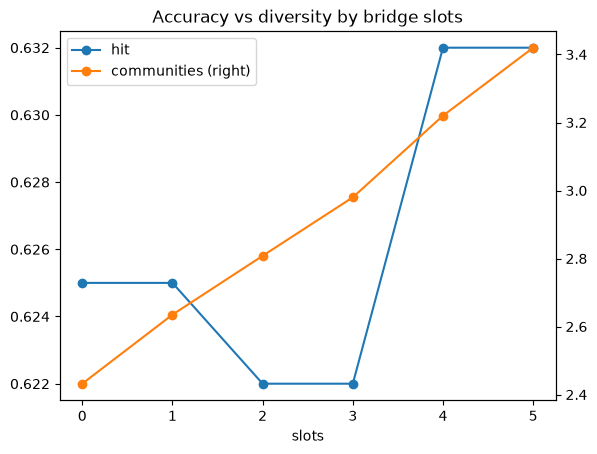

In [9]:
import time; t0 = time.time()
cache = {}
for u in sample:
    cache[u] = ppr_ranked(u)
print("PPR runs took", round(time.time() - t0), "s")

rows = []
for slots in range(0, 6):
    for u in sample:
        hid = hidden_ok[u]; home = tc[int(u2n[u])]
        r = cache[u].head(10).a.tolist() if slots == 0 else rec_aware(u, cache[u], slots=slots)
        cs = a2tc[r]
        rows.append(dict(slots=slots, hit=len(set(r) & hid) > 0, recall=len(set(r) & hid) / len(hid),
                         communities=cs.nunique(), outside=(cs != home).mean()))
sweep = pd.DataFrame(rows).groupby("slots").mean().round(3)
print(sweep)
sweep[["hit", "communities"]].plot(secondary_y="communities", marker="o", title="Accuracy vs diversity by bridge slots")

In [11]:
import os
import matplotlib.pyplot as plt
import pandas as pd, matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
def keep(name, fn):
    try: fn(); print("saved", name)
    except Exception as ex: print("SKIPPED", name, "->", type(ex).__name__, ex)

keep("PPR cache (400 users, 783 s of compute)", lambda: pd.concat(cache, names=["user", "rank"]).reset_index().to_csv("results/d_ppr_cache.csv", index=False))
keep("split",             lambda: e.to_csv("results/d_split.csv", index=False))
keep("eval per user",     lambda: res.to_csv("results/d_eval_per_user.csv", index=False))
keep("eval summary",      lambda: summary.to_csv("results/d_eval_summary.csv"))
keep("sweep",             lambda: sweep.to_csv("results/d_slots_sweep.csv"))
keep("train communities", lambda: tc.rename("community").to_csv("results/d_train_communities.csv"))
keep("bridge flags",      lambda: is_bridge.rename("is_bridge").to_csv("results/d_bridge_flags.csv"))

def fig_tradeoff():
    sweep[["hit", "communities"]].plot(secondary_y="communities", marker="o", title="Accuracy vs diversity by bridge slots")
    plt.savefig("figures/d_tradeoff.png", dpi=200, bbox_inches="tight"); plt.close("all")
keep("figure tradeoff", fig_tradeoff)

saved PPR cache (400 users, 783 s of compute)
saved split
saved eval per user
saved eval summary
saved sweep
saved train communities
saved bridge flags
saved figure tradeoff
